# Tasks for laboratory assignment 3

In [12]:
# imports section

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.preprocessing import PolynomialFeatures

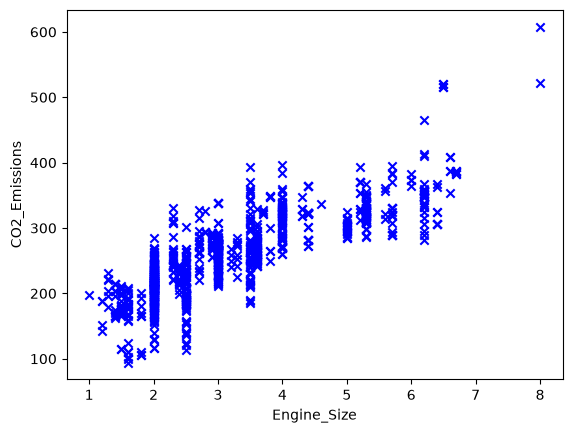

In [13]:
def build_plot(file_path, x, y):
    data = pd.read_csv(file_path)
    plt.scatter(data[x], data[y], c='blue', marker='x')
    plt.xlabel(x)
    plt.ylabel(y)
    return plt

build_plot('resources/CO2_emission.csv', 'Engine_Size', 'CO2_Emissions').show()

In [14]:
import pandas as pd

def extract_texts_from_file(file_path):
    """
    Extract the text data from the csv file

    Args:
        file_path (str): Relative location of the csv file in the project.

    Returns:
        list: The list of texts as strings.
    """
    df = pd.read_csv(file_path)
    return df.astype(str).agg(lambda x: ', '.join(x), axis=1).tolist()

data = extract_texts_from_file('resources/heart.csv')
print(data[:50])

['63, 1, 3, 145, 233, 1, 0, 150, 0, 2.3, 0, 0, 1, 1', '37, 1, 2, 130, 250, 0, 1, 187, 0, 3.5, 0, 0, 2, 1', '41, 0, 1, 130, 204, 0, 0, 172, 0, 1.4, 2, 0, 2, 1', '56, 1, 1, 120, 236, 0, 1, 178, 0, 0.8, 2, 0, 2, 1', '57, 0, 0, 120, 354, 0, 1, 163, 1, 0.6, 2, 0, 2, 1', '57, 1, 0, 140, 192, 0, 1, 148, 0, 0.4, 1, 0, 1, 1', '56, 0, 1, 140, 294, 0, 0, 153, 0, 1.3, 1, 0, 2, 1', '44, 1, 1, 120, 263, 0, 1, 173, 0, 0.0, 2, 0, 3, 1', '52, 1, 2, 172, 199, 1, 1, 162, 0, 0.5, 2, 0, 3, 1', '57, 1, 2, 150, 168, 0, 1, 174, 0, 1.6, 2, 0, 2, 1', '54, 1, 0, 140, 239, 0, 1, 160, 0, 1.2, 2, 0, 2, 1', '48, 0, 2, 130, 275, 0, 1, 139, 0, 0.2, 2, 0, 2, 1', '49, 1, 1, 130, 266, 0, 1, 171, 0, 0.6, 2, 0, 2, 1', '64, 1, 3, 110, 211, 0, 0, 144, 1, 1.8, 1, 0, 2, 1', '58, 0, 3, 150, 283, 1, 0, 162, 0, 1.0, 2, 0, 2, 1', '50, 0, 2, 120, 219, 0, 1, 158, 0, 1.6, 1, 0, 2, 1', '58, 0, 2, 120, 340, 0, 1, 172, 0, 0.0, 2, 0, 2, 1', '66, 0, 3, 150, 226, 0, 1, 114, 0, 2.6, 0, 0, 2, 1', '43, 1, 0, 150, 247, 0, 1, 171, 0, 1.5, 2, 0,

## CO2 emissions

Process file `CO2_emission.csv`. Build a model, that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

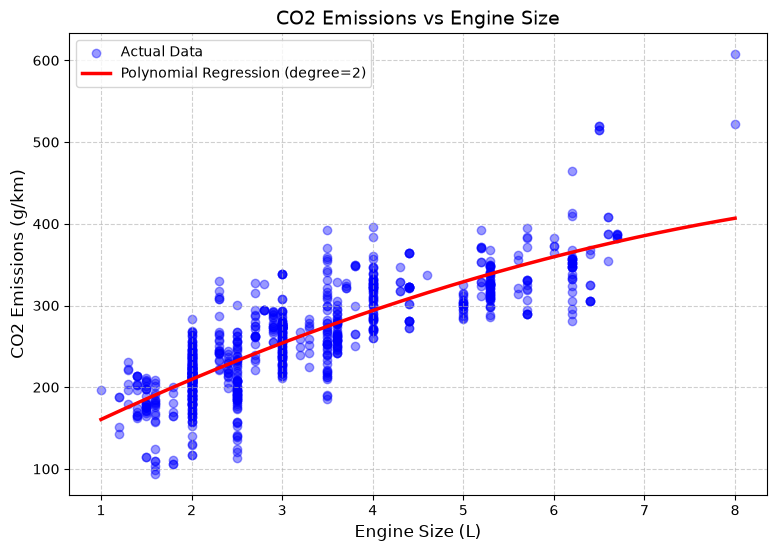

Model Theta Parameters (θ0, θ1, θ2): [106.80347772377942, 56.02580180646123, -2.315381879015206]


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

def extract_texts_from_file(file_path):
    """
    Extract data from CSV file into a pandas DataFrame.
    """
    return pd.read_csv(file_path)

def CO2_emissions(data):
    """
    Build a model that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

    Args:
        data: CO2 emissions data.

    Returns:
        list: The list of model theta parameters.
    """
    engine_col = [col for col in data.columns if 'engine' in col.lower()][0]
    co2_col = [col for col in data.columns if 'co2' in col.lower()][0]

    X = data[[engine_col]].values
    y = data[co2_col].values

    poly = PolynomialFeatures(degree=2)
    X_poly = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)

    theta = [float(model.intercept_)] + model.coef_[1:].tolist()

    plt.figure(figsize=(9, 6))
    plt.scatter(X, y, color='blue', alpha=0.4, label='Actual Data')

    X_plot = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
    y_plot = model.predict(poly.transform(X_plot))

    plt.plot(X_plot, y_plot, color='red', linewidth=2.5, label='Polynomial Regression (degree=2)')
    plt.title('CO2 Emissions vs Engine Size', fontsize=14)
    plt.xlabel('Engine Size (L)', fontsize=12)
    plt.ylabel('CO2 Emissions (g/km)', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

    return theta

data = extract_texts_from_file('resources/CO2_emission.csv')
theta_params = CO2_emissions(data)
print("Model Theta Parameters (θ0, θ1, θ2):", theta_params)

## Ice Cream Sales

Process file `ice_cream_selling_data.csv`. Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

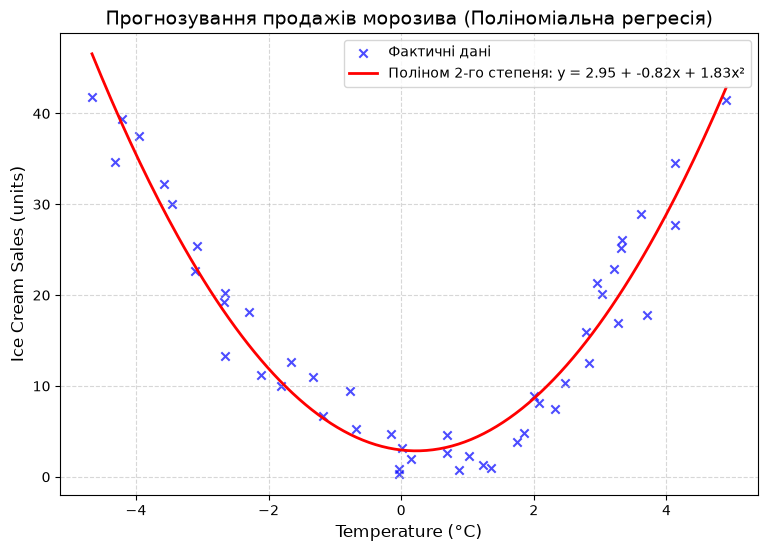

Параметри theta (θ0, θ1, θ2): [2.9517741579934498, -0.8246816702106483, 1.829526229670208]


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

def ice_cream_selling(data):
    """
    Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

    Args:
        data: ice cream sales data.

    Returns:
        list: The list of model theta parameters.
    """
    temp_col = [col for col in data.columns if 'temp' in col.lower()][0]
    sales_col = [col for col in data.columns if any(k in col.lower() for k in ['sale', 'revenue', 'ice'])][0]

    X = data[[temp_col]].values
    y = data[sales_col].values

    poly = PolynomialFeatures(degree=2)
    X_poly = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)

    theta = [float(model.intercept_)] + model.coef_[1:].tolist()

    plt.figure(figsize=(9, 6))
    plt.scatter(X, y, color='blue', marker='x', alpha=0.7, label='Фактичні дані')

    X_plot = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
    y_plot = model.predict(poly.transform(X_plot))

    plt.plot(X_plot, y_plot, color='red', linewidth=2, 
             label=f'Поліном 2-го степеня: y = {theta[0]:.2f} + {theta[1]:.2f}x + {theta[2]:.2f}x²')
    
    plt.xlabel(temp_col, fontsize=12)
    plt.ylabel(sales_col, fontsize=12)
    plt.title('Прогнозування продажів морозива (Поліноміальна регресія)', fontsize=14)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

    return theta

data = extract_texts_from_file('resources/ice_cream_selling_data.csv')
theta_params = ice_cream_selling(data)
print("Параметри theta (θ0, θ1, θ2):", theta_params)

## Electric Power Consumption

Process file `powerconsumption.csv`. Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

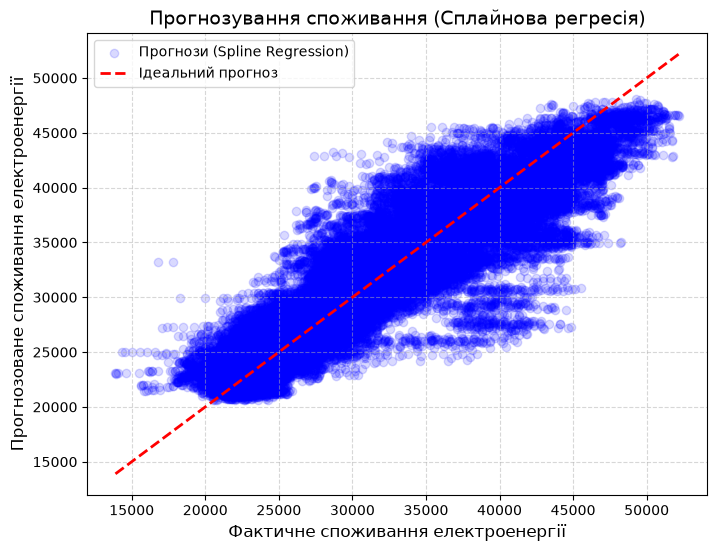

Кількість отриманих параметрів theta (θ0...θ28): 29


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import SplineTransformer
from sklearn.linear_model import Ridge

def power_consumption(data):
    """
    Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. 
    Visualize model on a plot.

    Args:
        data: power consumption data.

    Returns:
        list: The list of model theta parameters.
    """
    df = data.copy()

    temp_col = [col for col in df.columns if 'temp' in col.lower()][0]
    hum_col = [col for col in df.columns if 'humid' in col.lower()][0]
    wind_col = [col for col in df.columns if 'wind' in col.lower()][0]
    power_col = [col for col in df.columns if any(k in col.lower() for k in ['power', 'consump', 'zone'])][0]

    feature_cols = [temp_col, hum_col, wind_col]

    date_cols = [col for col in df.columns if any(k in col.lower() for k in ['date', 'time'])]
    if date_cols:
        date_col = date_cols[0]
        df[date_col] = pd.to_datetime(df[date_col])
        df['Hour'] = df[date_col].dt.hour
        feature_cols.append('Hour')

    X = df[feature_cols].values
    y = df[power_col].values

    # Сплайнове перетворення ознак (B-Splines)
    spline = SplineTransformer(n_knots=5, degree=3)
    X_spline = spline.fit_transform(X)

    model = Ridge(alpha=1.0)
    model.fit(X_spline, y)

    theta = [float(model.intercept_)] + [float(c) for c in model.coef_]

    y_pred = model.predict(X_spline)
    plt.figure(figsize=(8, 6))
    plt.scatter(y, y_pred, color='blue', alpha=0.15, label='Прогнози (Spline Regression)')

    min_val, max_val = min(y.min(), y_pred.min()), max(y.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ідеальний прогноз')

    plt.xlabel('Фактичне споживання електроенергії', fontsize=12)
    plt.ylabel('Прогнозоване споживання електроенергії', fontsize=12)
    plt.title('Прогнозування споживання (Сплайнова регресія)', fontsize=14)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

    return theta


# Виклик функції
data = extract_texts_from_file('resources/powerconsumption.csv')
theta_params = power_consumption(data)
print(f"Кількість отриманих параметрів theta (θ0...θ{len(theta_params)-1}):", len(theta_params))

## Heart Conditions Predictions

Process file `heart.csv`. It has the following data:

- age - Age of the patient
- sex - Sex of the patient
- cp - Chest pain type ~ 0 = Typical Angina, 1 = Atypical Angina, 2 = Non-anginal Pain, 3 = Asymptomatic
- trtbps - Resting blood pressure (in mm Hg)
- chol - Cholestoral in mg/dl fetched via BMI sensor
- fbs - (fasting blood sugar > 120 mg/dl) ~ 1 = True, 0 = False
- restecg - Resting electrocardiographic results ~ 0 = Normal, 1 = ST-T wave normality, 2 = Left ventricular hypertrophy
- thalachh - Maximum heart rate achieved
- oldpeak - Previous peak
- slp - Slope
- caa - Number of major vessels
- thall - Thalium Stress Test result ~ (0,3)
- exng - Exercise induced angina ~ 1 = Yes, 0 = No
- output - Target variable - risk of heart attack - 1 is high chance of heart attack and 0 is low chance.

Use classification model (choose model best fitting model yourself). Choose parameters that would best fit for making a prediction on. Visualize model on a plot.

Do not forget to split data into train data and validation data. Validate your model.

Validation Accuracy: 0.8033

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.68      0.76        28
           1       0.77      0.91      0.83        33

    accuracy                           0.80        61
   macro avg       0.82      0.79      0.80        61
weighted avg       0.81      0.80      0.80        61



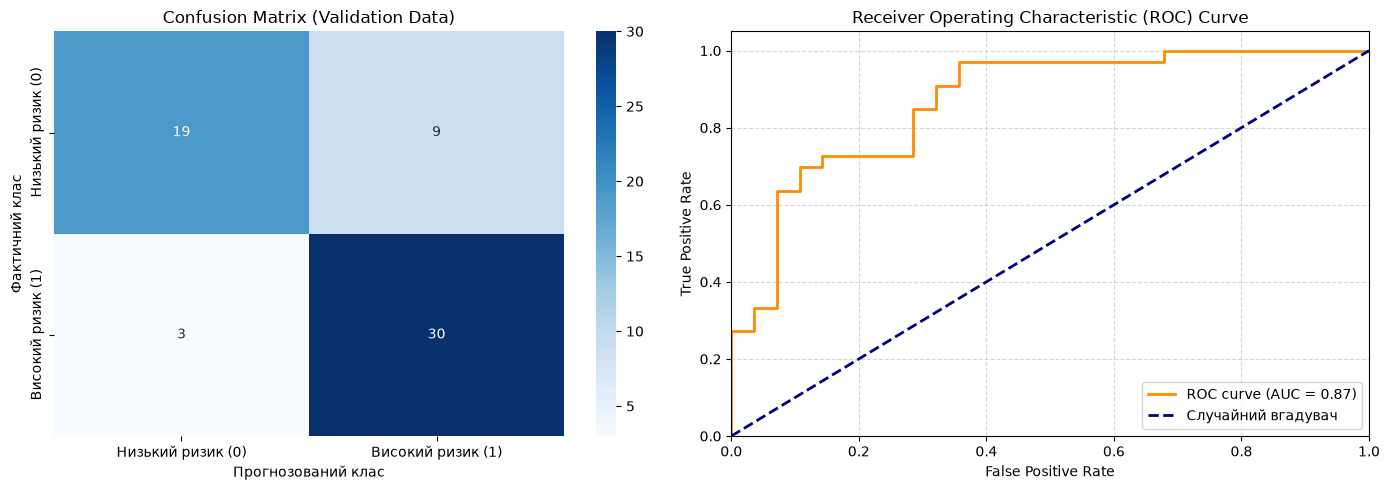

Параметри theta (θ0, θ1, ..., θn): [0.13159523820583105, 0.01773589269520605, -0.7140301567978149, 0.937735440424474, -0.2114365918793342, -0.45921005774158996, -0.06364885983507027, 0.23547145007020678, 0.5396293104526307, -0.4758830163823866, -0.5948186666294085, 0.3078670529788831, -0.5592027955256132, -0.6215780683618346]


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

def heart_classification(data):
    """
    Build a model, that would classify risk category for heart attack. 
    Visualize model on a plot.

    Args:
        data: heart medical data.

    Returns:
        list: The list of model theta parameters.
    """

    target_col = [col for col in data.columns if col.lower() in ['output', 'target']][0]
    
    X = data.drop(columns=[target_col])
    y = data[target_col]

    X_train, X_val, y_train, y_val = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    model = LogisticRegression(random_state=42, max_iter=1000)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_val_scaled)
    y_prob = model.predict_proba(X_val_scaled)[:, 1]
    
    print(f"Validation Accuracy: {accuracy_score(y_val, y_pred):.4f}\n")
    print("Classification Report:")
    print(classification_report(y_val, y_pred))

    theta = [float(model.intercept_[0])] + [float(coef) for coef in model.coef_[0]]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    cm = confusion_matrix(y_val, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['Низький ризик (0)', 'Високий ризик (1)'],
                yticklabels=['Низький ризик (0)', 'Високий ризик (1)'])
    axes[0].set_title('Confusion Matrix (Validation Data)', fontsize=12)
    axes[0].set_xlabel('Прогнозований клас')
    axes[0].set_ylabel('Фактичний клас')

    fpr, tpr, _ = roc_curve(y_val, y_prob)
    roc_auc = auc(fpr, tpr)
    axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
    axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Случайний вгадувач')
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel('False Positive Rate')
    axes[1].set_ylabel('True Positive Rate')
    axes[1].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=12)
    axes[1].legend(loc="lower right")
    axes[1].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

    return theta


# Виклик функції
data = extract_texts_from_file('resources/heart.csv')
theta_params = heart_classification(data)
print("Параметри theta (θ0, θ1, ..., θn):", theta_params)

## Additional (extra credit)

There are more files in the resources folder. Take a look at the. Visualize data in these files. Choose ML algorithm for building a model and making predictions for new data. Visualize the model.

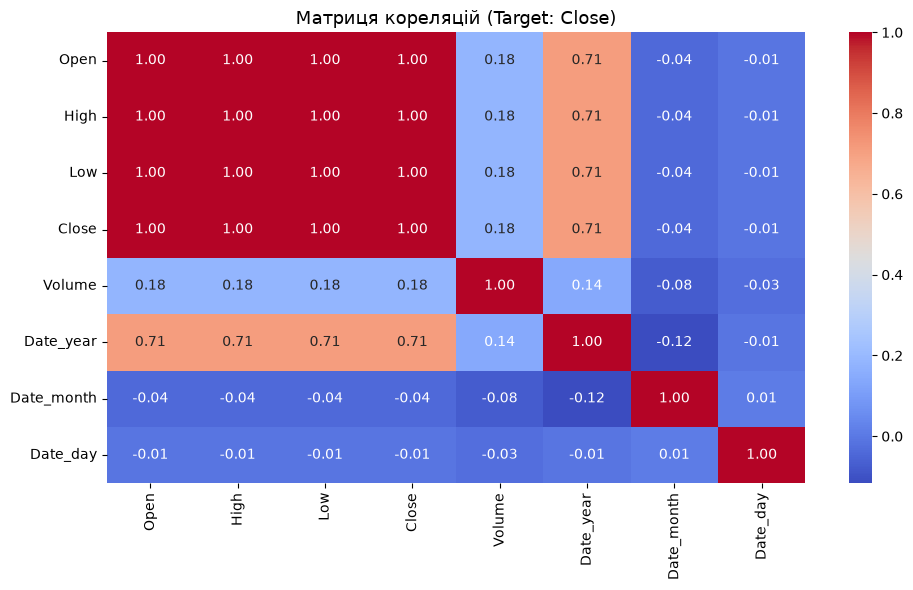

--- Результати Регресії ---
Коефіцієнт детермінації R²: 0.9994
RMSE: 388.8957



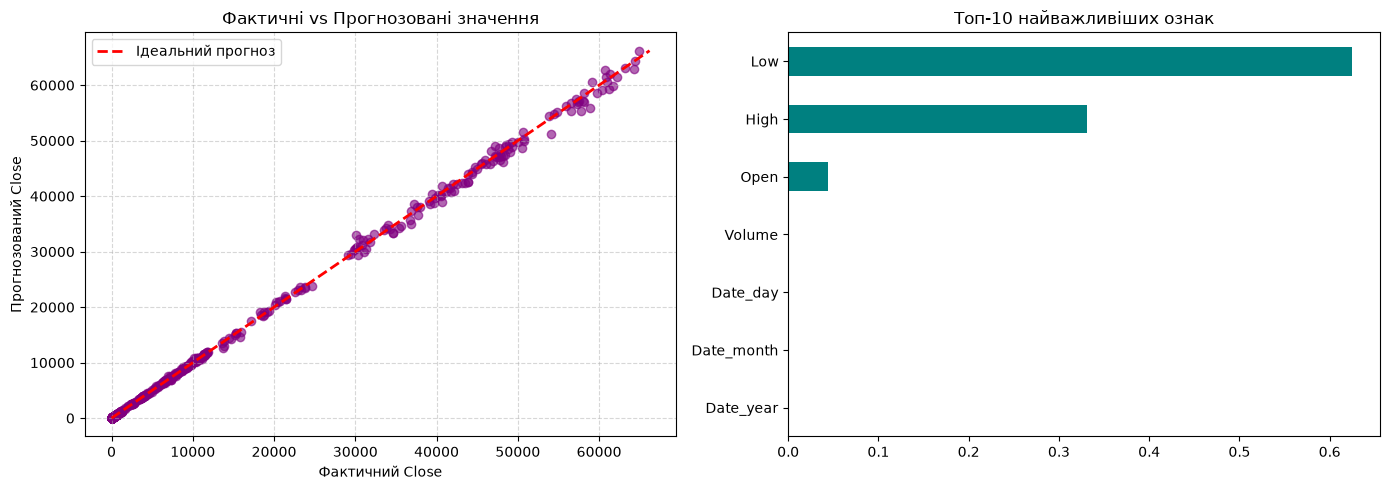

{'model': RandomForestRegressor(random_state=42),
 'r2_score': 0.9993711446446008,
 'rmse': np.float64(388.89573713133484)}

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix

def additional(data):
    df = data.copy()

    for col in df.select_dtypes(include=['object', 'string']).columns:
        try:
            date_series = pd.to_datetime(df[col])
            df[f'{col}_year'] = date_series.dt.year
            df[f'{col}_month'] = date_series.dt.month
            df[f'{col}_day'] = date_series.dt.day
            df = df.drop(columns=[col])
        except Exception:
            if df[col].nunique() > 50:
                df = df.drop(columns=[col])

    df_encoded = pd.get_dummies(df, drop_first=True)

    target_candidates = [c for c in df_encoded.columns if any(k in c.lower() for k in ['close', 'price', 'target'])]
    target_col = target_candidates[0] if target_candidates else df_encoded.columns[-1]

    X = df_encoded.drop(columns=[target_col])
    y = df_encoded[target_col]

    is_classification = (y.nunique() <= 10) or (y.dtype == 'bool')

    plt.figure(figsize=(10, 6))
    cols_to_corr = df_encoded.columns[:15] if len(df_encoded.columns) > 15 else df_encoded.columns
    sns.heatmap(df_encoded[cols_to_corr].corr(), annot=True, fmt='.2f', cmap='coolwarm', cbar=True)
    plt.title(f'Матриця кореляцій (Target: {target_col})', fontsize=13)
    plt.tight_layout()
    plt.show()

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y if is_classification else None
    )

    if is_classification:
        model = RandomForestClassifier(n_estimators=100, random_state=42)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        acc = accuracy_score(y_test, y_pred)
        print(f"--- Результати Класифікації ---")
        print(f"Точність (Accuracy): {acc:.4f}\n")

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
        axes[0].set_title('Матриця помилок (Confusion Matrix)')

        feat_importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=True)
        feat_importances.tail(10).plot(kind='barh', ax=axes[1], color='teal')
        axes[1].set_title('Топ-10 найважливіших ознак')
        
        plt.tight_layout()
        plt.show()
        return {"model": model, "accuracy": acc}

    else:
        model = RandomForestRegressor(n_estimators=100, random_state=42)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        r2 = r2_score(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        print(f"--- Результати Регресії ---")
        print(f"Коефіцієнт детермінації R²: {r2:.4f}")
        print(f"RMSE: {rmse:.4f}\n")

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        axes[0].scatter(y_test, y_pred, alpha=0.6, color='purple')
        min_v, max_v = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
        axes[0].plot([min_v, max_v], [min_v, max_v], 'r--', lw=2, label='Ідеальний прогноз')
        axes[0].set_xlabel(f'Фактичний {target_col}')
        axes[0].set_ylabel(f'Прогнозований {target_col}')
        axes[0].set_title('Фактичні vs Прогнозовані значення')
        axes[0].legend()
        axes[0].grid(True, linestyle='--', alpha=0.5)

        feat_importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=True)
        feat_importances.tail(10).plot(kind='barh', ax=axes[1], color='teal')
        axes[1].set_title('Топ-10 найважливіших ознак')

        plt.tight_layout()
        plt.show()
        return {"model": model, "r2_score": r2, "rmse": rmse}

data = extract_texts_from_file('resources/bitcoin.csv')
additional(data)

## Machine learning analysis on texts

Predict text score (sentiment, holistic score, etc., any other target label) using machine learning algorithm you see best fit for the task. Choose kaggle dataset from available below. Display classification report (confusion matrix, accuracy, f1 score, etc.). 

- Learning Agency Lab - Automated Essay Scoring 2.0: predict holistic text score given full_text (student essays) https://www.kaggle.com/competitions/learning-agency-lab-automated-essay-scoring-2
- 100K Coursera's Course Reviews Dataset: predict the final rating (1 to 5) based on the text of the review https://www.kaggle.com/datasets/septa97/100k-courseras-course-reviews-dataset
- LLM - Detect AI Generated Text: predict the target label (0 being written by student and 1 being written by LLM) given the full text https://www.kaggle.com/competitions/llm-detect-ai-generated-text
- 42K+ Udemy Course Enrollment Information Dataset🔥: classify course categories using Title and Summary; compare text-only features against combined title-and-summary features https://www.kaggle.com/datasets/songseungwon/2020-udemy-courses-dataset
- TMDB 5000 Movie Dataset: movie classification based on description https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?select=tmdb_5000_movies.csv



Selected Text Column: 'Review' | Target Column: 'Label'

Overall Accuracy: 0.4594
Weighted F1 Score: 0.4552
Macro F1 Score: 0.4553

Classification Report:
              precision    recall  f1-score   support

           1       0.53      0.60      0.57       450
           2       0.35      0.36      0.36       450
           3       0.37      0.34      0.35       450
           4       0.41      0.36      0.38       451
           5       0.60      0.64      0.62       450

    accuracy                           0.46      2251
   macro avg       0.45      0.46      0.46      2251
weighted avg       0.45      0.46      0.46      2251



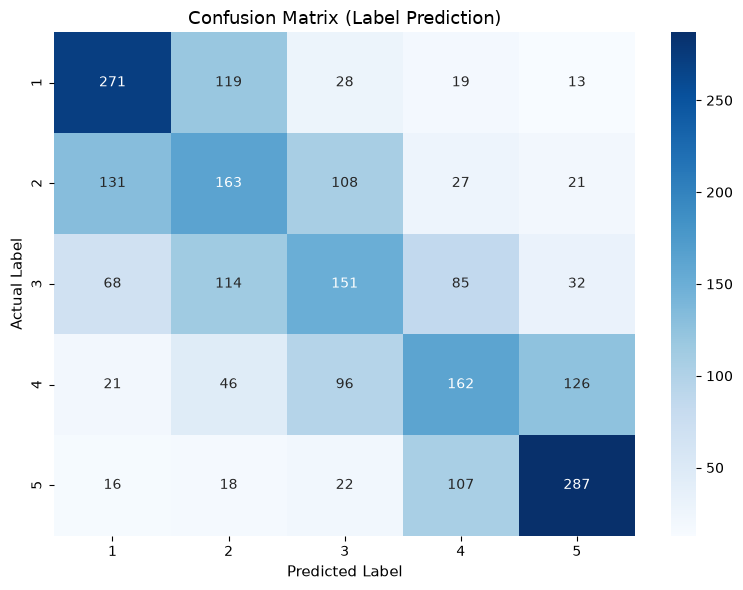

In [37]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split

try:
    import kagglehub
    from kagglehub import KaggleDatasetAdapter
except ImportError:
    kagglehub = None


def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """

    try:
        if kagglehub is not None:
            folder_path = kagglehub.dataset_download(url)
            file_path = os.path.join(folder_path, csv_file)
            if os.path.exists(file_path):
                return pd.read_csv(file_path, encoding='latin1')
    except Exception as e:
        print(f"Kagglehub download error: {e}. Спроба знайти локальний файл...")

    local_path = os.path.join("resources", csv_file)
    if os.path.exists(local_path):
        try:
            return pd.read_csv(local_path, encoding='utf-8')
        except UnicodeDecodeError:
            return pd.read_csv(local_path, encoding='latin1')

    raise FileNotFoundError(
        f"Файл '{csv_file}' не знайдено в кеші Kaggle та у папці '{local_path}'. "
        f"Завантажте його вручну з веб-сторінки Kaggle та помістіть у папку resources/"
    )


def classify_text_ml(df):
    """
    Classify text data using a machine learning model.

    Args:
        df (pd.DataFrame): The input DataFrame containing text data.

    Returns:
        None
    """

    text_col = [col for col in df.columns if any(k in col.lower() for k in ["text", "review", "essay", "summary", "title"])][0]
    target_col = [col for col in df.columns if any(k in col.lower() for k in ["rating", "score", "label", "target", "category"])][0]

    print(f"Selected Text Column: '{text_col}' | Target Column: '{target_col}'")

    df_clean = df[[text_col, target_col]].dropna().copy()
    df_clean[text_col] = df_clean[text_col].astype(str)
    
    if pd.api.types.is_numeric_dtype(df_clean[target_col]):
        df_clean[target_col] = df_clean[target_col].astype(int)

    # Надійне балансування вибірки без втрати цільової колонки
    if len(df_clean) > 20000:
        min_class_size = df_clean[target_col].value_counts().min()
        max_samples_per_class = min(4000, max(min_class_size, 1500))
        
        sampled_parts = []
        for name, group in df_clean.groupby(target_col):
            n_samples = min(len(group), max_samples_per_class)
            sampled_parts.append(group.sample(n=n_samples, random_state=42))
        
        df_clean = pd.concat(sampled_parts, ignore_index=True)

    X = df_clean[text_col]
    y = df_clean[target_col]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    vectorizer = TfidfVectorizer(
        max_features=10000, 
        stop_words="english", 
        ngram_range=(1, 2),
        sublinear_tf=True
    )
    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_test_tfidf = vectorizer.transform(X_test)

    model = LogisticRegression(
        max_iter=1000, 
        random_state=42, 
        solver="lbfgs", 
        class_weight="balanced",
        C=1.0
    )
    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    acc = accuracy_score(y_test, y_pred)
    f1_weighted = f1_score(y_test, y_pred, average="weighted")
    f1_macro = f1_score(y_test, y_pred, average="macro")

    print("\n" + "=" * 50)
    print(f"Overall Accuracy: {acc:.4f}")
    print(f"Weighted F1 Score: {f1_weighted:.4f}")
    print(f"Macro F1 Score: {f1_macro:.4f}")
    print("=" * 50 + "\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=np.unique(y),
        yticklabels=np.unique(y),
    )
    plt.title(f"Confusion Matrix ({target_col} Prediction)", fontsize=13)
    plt.xlabel("Predicted Label", fontsize=11)
    plt.ylabel("Actual Label", fontsize=11)
    plt.tight_layout()
    plt.show()

df = load_dataset("septa97/100k-courseras-course-reviews-dataset", "reviews.csv")
classify_text_ml(df)